CNNs anf GNNs as classifiers for sparse data events#
##Tutorial - Hands-on

**Scope:** learn how to design and train a CNN and GNN architectures for a classification task

**Tasks:** <p>
Jet tagging (e.g. classification of jets originating from different particles: *gluons, quarks, Ws, Zs, and top quarks*).

**Physics context:** <p>
At the extreme energies of the Large Hadron Collider, massive particles can be produced with such high Lorentz boost that their decays into hadrons (hadron jets) are collimated in such a way that the resulting particles overlap. Deducing whether the substructure of an observed jet is due to a single low-mass particle or to multiple decay objects of a high-mass particle is an important problem in LHC data analysis. Traditional approaches are based on high-level observables built from theoretical models of energy deposition in calorimeters and charged tracks parameters reconsrtcuted in the inner tracker, but the complexity of the data makes this task an excellent candidate for the application of deep learning tools. The jet constituents can be in fact represented either as 2D or ND images,lending itself to the natural application of image classification techniques (CNN, ViT etc.), or as pointclouds/graphs, that can be classified with GNNs, or also as sequences, that can be analysed by RNNs or Transformers.

1.   create image-like and graph-like structures to represent jets from decays of different particles at an hadron collider using the *JetDataset*
2.   design and train a CNN architecture to classify jet image in one of the 5 categories: jet from [g,q,W,Z,t]
3.   design and train a GNN architecture (PointNet++) to classify jet graphs in one of the 5 categories: jet from [g,q,W,Z,t]
4.   assess performances of the two trained models

In [ ]:
#imports
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import glob

## Dataset:
The problem consists in identifying a given jet as a quark, a gluon, a W, a Z, or a top, based either on a **jet image**, i.e., a **2D histogram of the transverse momentum ($p_T$) deposited in each of 100x100 bins of a square window of the ($\eta,\phi$) plane, centered along the jet axis**, or on a **jet graph** structure, eg a graph with nodes the jet constituents

The jet constituents are stored in the **features** numpy array of shape (20000,100,16), where 100 is the number of jet constituents (if smaller than 100 is zero-padded to 100, if larger si trimmed to 100). and 16 is the number of features associated to each particle:

* the four-momentum in cartesian coordinates $(p_x,p_y,p_z,E)$
* the energy divided by the jet energy ($E_{rel}$)
* the transverse momentum ($p_T$), i.e. the momentum projected on the plane transverse to proton beams
* the momentum transverse to the jet direction ($p_{Trel}$)
* the pseudorapidity ($\eta$), a function of the polar angle (see https://en.wikipedia.org/wiki/Pseudorapidity)
* the pseudorapidity relative to the jet direction ($\eta_{rel}$)
* the pseudorapidity relative to the jet direction ($\eta_{rot}$) after a rotation is applied so that the jet image looks vertical
* the azimuth angle ($\phi$)
* the azimuth angle relative to the jet direction ($\phi_{rel}$)
* the azimuth angle relative to the jet direction ($\phi_{rot}$) after a rotation is applied so that the jet image looks vertical
* the $\Delta R = \sqrt{(\Delta\eta_{max})^2 + (\Delta\phi_{max})^2}$ of the jet
* the $\cos\theta$ of the jet
* the $\cos\theta_{rel}$ of the jet

The ground truth is incorporated in a **target** (['j_g', 'j_q', 'j_w', 'j_z', 'j_t]) numpy array of boolean with shape (20000,5) encoding the labels such that:

* $[1, 0, 0, 0, 0]$ for gluons
* $[0, 1, 0, 0, 0]$ for quarks
* $[0, 0, 1, 0, 0]$ f
or W bosons (with W -> qq)
* $[0, 0, 0, 1, 0]$ for Z bosons (with Z -> qq)
* $[0, 0, 0, 0, 1]$ for top quarks (with t -> Wq -> qqq)

This is what is called 'one-hot' encoding of a discrete label (typical of ground truth for classification problems).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/Shareddrives/Statistics\ and\ Data\ Analysis/Lectures/DL lectures/Lecture 16/Examples/
!ls

Mounted at /content/drive
/content/drive/Shareddrives/Statistics and Data Analysis/Lectures/DL lectures/Lecture 16/Examples
best_model_gnn.pth  data  GNN_JetTagging_HandsOn.ipynb


In [ ]:
# read dataset
with np.load('data/dataset_jetTag.npz') as f:
  print(f.files)
  target = f['target']
  features = f['features']

# convert one-hot lables in integers labels (easier to manage in pytorch)
label = np.argmax(target, axis=1)

print(target.shape, label.shape, features.shape)

['target', 'features']
(20000, 5) (20000,) (20000, 100, 16)


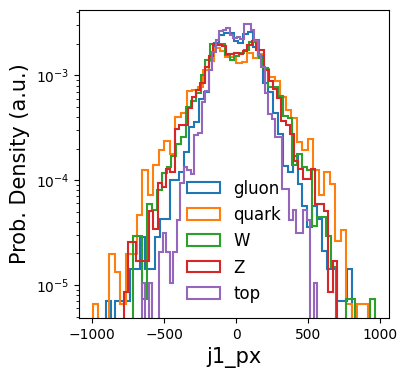

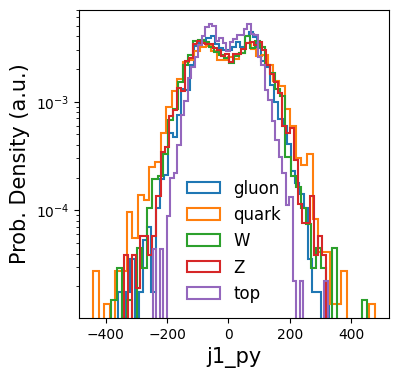

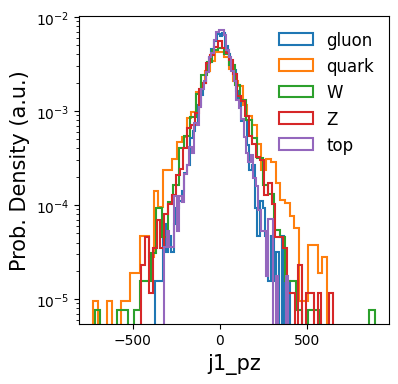

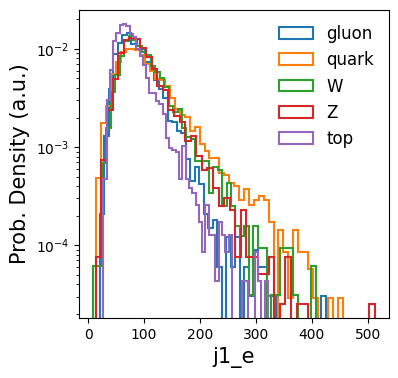

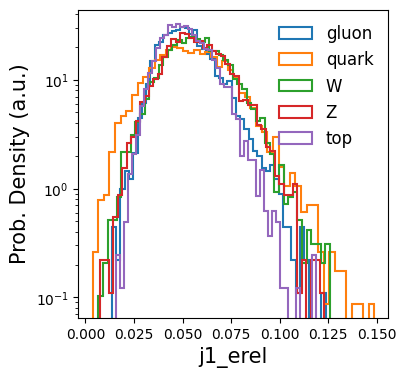

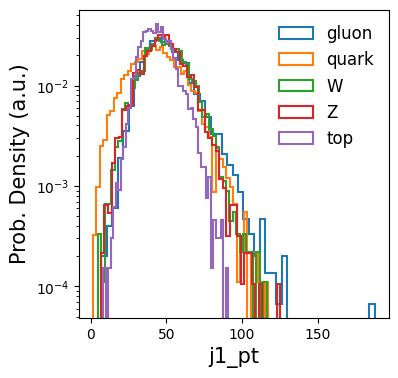

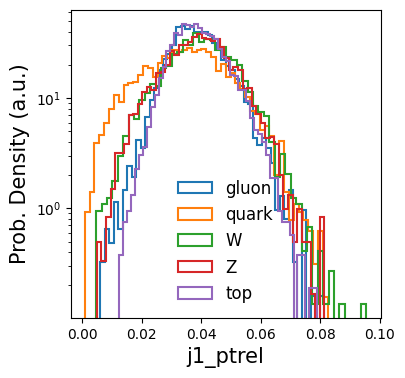

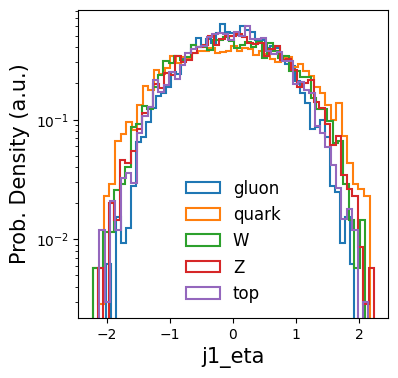

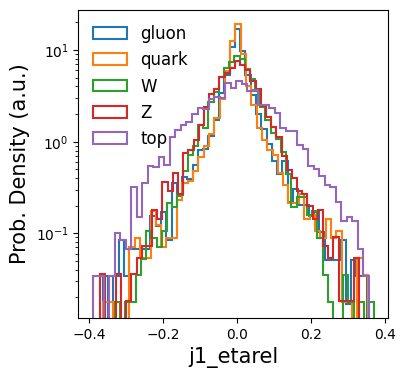

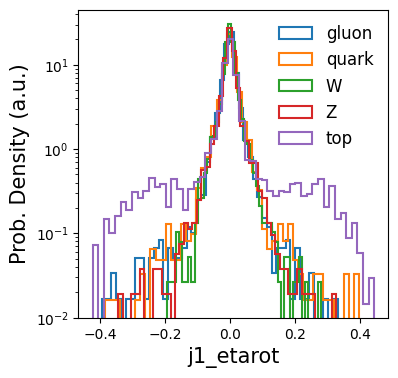

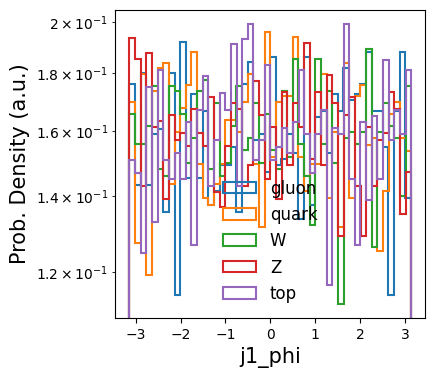

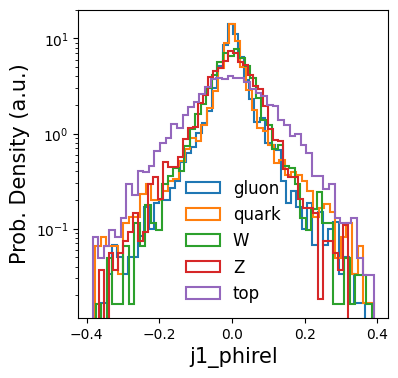

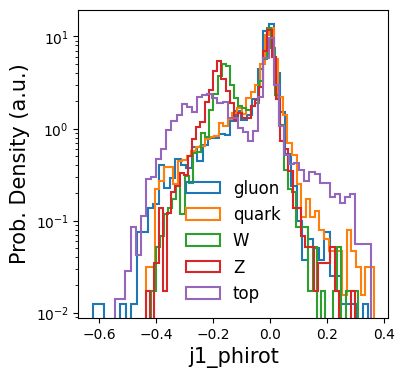

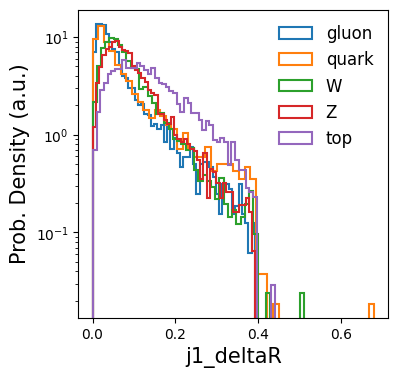

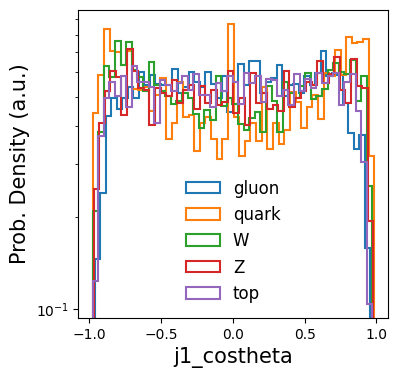

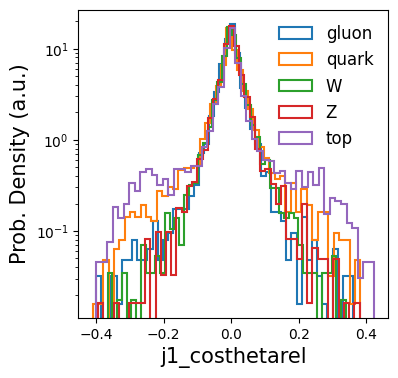

In [ ]:
# plot of the features:

# this function makes the histogram of a given quantity for the five classes
def makePlot_p(feature_index, input_data, input_featurenames, labels):
    plt.subplots(figsize=(4,4))
    for i in range(len(labels)):
        my_data = input_data[:,:,feature_index]
        # notice the use of numpy masking to select specific classes of jets
        my_data = my_data[np.argmax(target, axis=1) == i]
        # then plot the right quantity for the reduced array
        plt.hist(my_data[:,feature_index].flatten(), 50, density=True, histtype='step', fill=False, linewidth=1.5)
    plt.yscale('log', nonpositive='clip', )
    plt.legend(labels, fontsize=12, frameon=False)
    plt.xlabel(input_featurenames[feature_index], fontsize=15)
    plt.ylabel('Prob. Density (a.u.)', fontsize=15)
    plt.show()

featurenames = ['j1_px','j1_py','j1_pz','j1_e','j1_erel','j1_pt','j1_ptrel',
 'j1_eta','j1_etarel','j1_etarot','j1_phi','j1_phirel','j1_phirot',
 'j1_deltaR','j1_costheta','j1_costhetarel']

labels_str = ['gluon', 'quark', 'W', 'Z', 'top']

# we now plot all the features
for i in range(len(featurenames)):
    makePlot_p(i, features, featurenames, labels_str)

In [ ]:
# create jet "images": eg project each particle $p_T$ in a 100x100 eta,phi grid ceneterd around the jet direction
def create_images(features):
    jet_imgs = np.empty((features.shape[0],100,100))

    for i in range(features.shape[0]):
      eta = features[i,:,8]
      phi = features[i,:,11]
      pt = features[i,:,5]
      h,_,_ = np.histogram2d(phi,eta,bins=100,range=[[-1,1],[-1,1]], weights=pt)
      jet_imgs[i] = h

    return jet_imgs
# split in train, validation and test sets
from sklearn.model_selection import train_test_split

# Split into training and remaining dataset
X_train, X_rem, y_train, y_rem = train_test_split(features, label, train_size=0.8, random_state=42)
X_valid, X_test, y_valid, y_test = train_test_split(X_rem, y_rem, test_size=0.5, random_state=42)

print(X_train.shape), print(y_train.shape)
print(X_valid.shape), print(y_valid.shape)
print(X_test.shape), print(y_test.shape)

jet_imgs_train = create_images(X_train)
jet_imgs_valid = create_images(X_valid)
jet_imgs_test = create_images(X_test)


(16000, 100, 16)
(16000,)
(2000, 100, 16)
(2000,)
(2000, 100, 16)
(2000,)


In [ ]:
print(jet_imgs_train[1028])

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


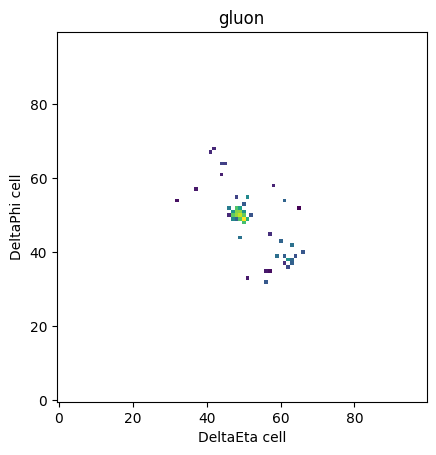

In [ ]:
sample_index = 1028

# print one jet image
# plot a single image to display the sparsity
from matplotlib.colors import LogNorm

def plot_single_image(jet_imgs,label,i=1):
    plt.imshow(jet_imgs[i], origin='lower', norm=LogNorm())
    plt.title(labels_str[label[i]])
    plt.xlabel('DeltaEta cell')
    plt.ylabel('DeltaPhi cell')
    plt.show()

plot_single_image(jet_imgs_train,y_train,i=sample_index)

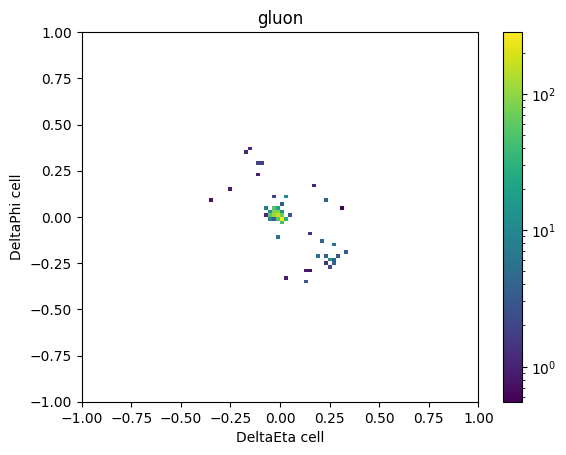

In [ ]:
#plot the same event in relative eta/phi wrt the jet direction

particle_eta = X_train[sample_index,:,8]
particle_phi = X_train[sample_index,:,11]
particle_pt = X_train[sample_index,:,5]

#invert x and y to follow what imshow does on the np.histogram2d
plt.hist2d(particle_eta, particle_phi, bins=100, weights=particle_pt, range=[[-1,1],[-1,1]], norm=LogNorm())
plt.title(labels_str[label[sample_index]])
plt.xlabel('DeltaEta cell')
plt.ylabel('DeltaPhi cell')
plt.colorbar()
plt.show()

In [ ]:
jet_imgs_train[0].shape

(100, 100)

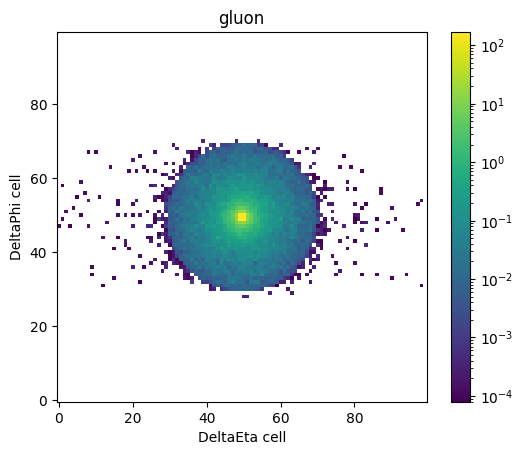

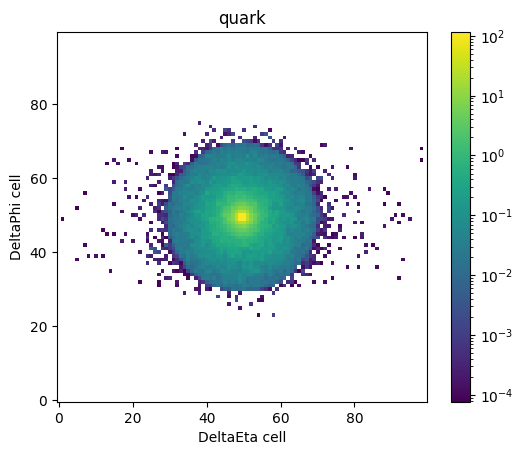

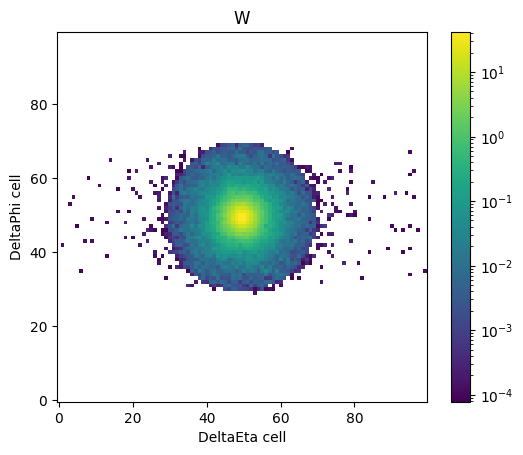

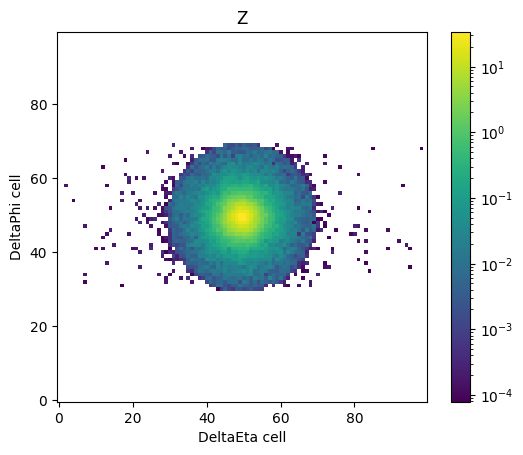

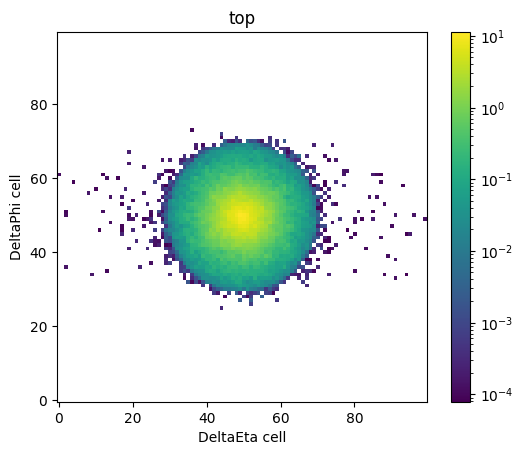

In [ ]:
# plots of sum of jet images for different jet catagories
def plot_sum_images(jet_imgs,label,labels_str):
    image_g = jet_imgs[label==0]
    image_q = jet_imgs[label==1]
    image_W = jet_imgs[label==2]
    image_Z = jet_imgs[label==3]
    image_t = jet_imgs[label==4]
    images = [image_q, image_g, image_W, image_Z, image_t]

    for i in range(len(images)):
        SUM_Image = np.sum(images[i], axis = 0)
        plt.imshow(SUM_Image/float(images[i].shape[0]), origin='lower', norm=LogNorm())
        plt.colorbar()
        plt.title(labels_str[i])
        plt.xlabel('DeltaEta cell')
        plt.ylabel('DeltaPhi cell')
        plt.show()
plot_sum_images(jet_imgs_train,y_train,labels_str)

# GNN Model

In [ ]:
import torch

# automatically get what versions of torch and cuda are being used
PYT = torch.__version__.split('+')[0]
CUDA = torch.version.cuda.replace('.', '')

print(f"Versione PyTorch: {PYT}")
print(f"Versione CUDA: {CUDA}")

# install dependencies using pre-compiled bianries to save time
!pip install torch-scatter torch-sparse torch-cluster torch-spline-conv -f https://data.pyg.org/whl/torch-{PYT}+cu{CUDA}.html
!pip install torch-geometric

Versione PyTorch: 2.10.0
Versione CUDA: 128
Looking in links: https://data.pyg.org/whl/torch-2.10.0+cu128.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 88.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 101.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 95.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 57.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 36.1 MB/s eta 0:00:00


In [ ]:
# create a custom graph dataset to hold the jet data
#
# Well use eta-phi rel coordinates to build the graph structure, linking via k-nn nodes (eg jet constituents) that are spatially close, and associate to
# each node a feature vector given by each particle feature vector

import torch_geometric
from torch_geometric.data import Data, Dataset
from torch_geometric.loader import DataLoader
from torch_geometric.transforms import FixedPoints
from sklearn.model_selection import train_test_split
from torch_cluster import knn_graph

In [ ]:
print(torch_geometric.__version__)
print(type(Dataset))
print(Dataset.__module__)

2.7.0
<class 'type'>
torch_geometric.data.dataset


In [ ]:
class MyGraphDataset(torch_geometric.data.Dataset):
    def __init__(self, data_f, data_l, k=15, transform=None, pre_transform=None):
        super(MyGraphDataset, self).__init__(transform, pre_transform)
        self.data_f = data_f
        self.data_l = data_l
        self.num_samples = len(data_f)
        self.k = k # number of nearest neighbors

    def len(self):
        return self.num_samples

    def get(self, idx):

        graph_data = self.data_f[idx]
        graph_label = self.data_l[idx]

        # select real jet constituents (eg with pt>0) --> get rid of the patting to 100 particles per jet
        sel = graph_data[:,5]>0


        pos_tmp = graph_data[sel]
        pos = torch.tensor(pos_tmp[:,[8,11]], dtype=torch.float32) #eta_rel and phi_rel
        x   = torch.tensor(np.log(pos_tmp[:,5]), dtype=torch.float32)/5 #pt (you can add easily as many features as you like)
        #x   = torch.tensor((pos_tmp[:,5]), dtype=torch.float32). #pt (you can add easily as many features as you like)
        y   = torch.tensor(np.asarray(graph_label), dtype=torch.long) #targets
        category = torch.tensor(np.asarray(graph_label), dtype=torch.long)

        # compute edge_index (using pos)
        edge_index = knn_graph(pos, k=self.k, loop=False)

        # pyg data object
        data = Data(x=x, y=y, pos=pos, edge_index=edge_index, category=category)

        return data


# same split as CNN

print("train: "),print(X_train.shape), print(y_train.shape)
print("vali: "),print(X_valid.shape), print(y_valid.shape)
print("test: "),print(X_test.shape), print(y_test.shape)


train: 
(16000, 100, 16)
(16000,)
vali: 
(2000, 100, 16)
(2000,)
test: 
(2000, 100, 16)
(2000,)


(None, None, None)

In [ ]:
# number of nearest neighbors at the end of the network
k = 8

# Create Datasets
trainset = MyGraphDataset(X_train, y_train, k=k)
validset = MyGraphDataset(X_valid, y_valid, k=k)
testset = MyGraphDataset(X_test, y_test, k=k)

# Create DataLoaders
trainloader = DataLoader(trainset, batch_size=256, shuffle=True, drop_last=True, num_workers=2)
validloader = DataLoader(validset, batch_size=256, shuffle=False, drop_last=False, num_workers=2)
testloader = DataLoader(testset, batch_size=4, shuffle=False, drop_last=False)

In [ ]:
trainset[0]

Data(x=[30], edge_index=[2, 240], y=1, pos=[30, 2], category=1)

In [ ]:
data = next(iter(trainloader))

In [ ]:
data.batch

tensor([  0,   0,   0,  ..., 255, 255, 255])

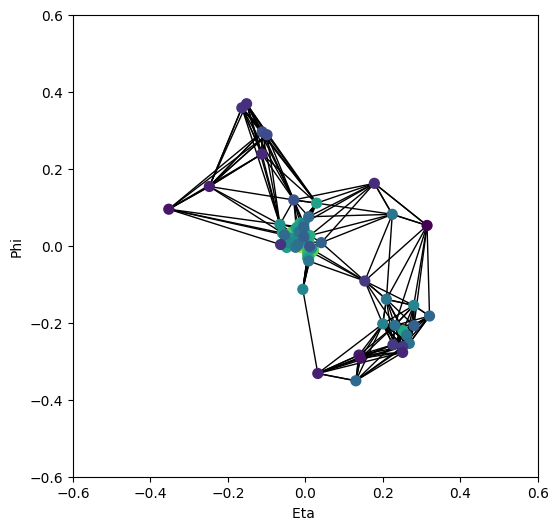

In [ ]:
def visualize_points(pos, x, edge_index=None):
    fig = plt.figure(figsize=(6, 6))
    if edge_index is not None:
        for (src, dst) in edge_index.t().tolist():
             src = pos[src].tolist()
             dst = pos[dst].tolist()
             plt.plot([src[0], dst[0]], [src[1], dst[1]], linewidth=1, color='black')


    plt.scatter(pos[:, 0], pos[:, 1], s=50, c =(x), zorder=1000)

    plt.xlim((-0.6,0.6))
    plt.ylim((-0.6,0.6))
    plt.xlabel('Eta ')
    plt.ylabel('Phi')
    plt.show()

data = trainset[sample_index]

visualize_points(data.pos, data.x, data.edge_index)

In [ ]:
from matplotlib import colors as mcolors
colors = list(mcolors.TABLEAU_COLORS.keys())
def get_color(index):
    wrapped_index = index % len(colors)
    return colors[wrapped_index]

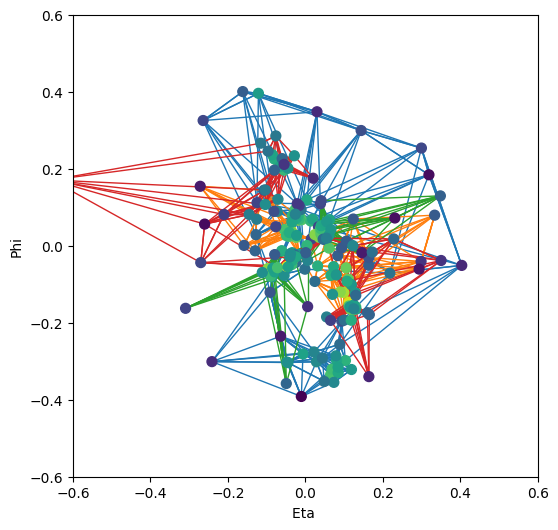

In [ ]:
# visualize a batch

def visualize_batch(pos, x, edge_index=None, batch=None):
    fig = plt.figure(figsize=(6, 6))

    if edge_index is not None:
        for (src, dst) in edge_index.t().tolist():
             if batch is not None:
                 c=get_color(batch[src])
             else:
                 c="black"
             src = pos[src].tolist()
             dst = pos[dst].tolist()

             plt.plot([src[0], dst[0]], [src[1], dst[1]], linewidth=1, color=c)


    plt.scatter(pos[:, 0], pos[:, 1], s=50, c =(x), zorder=1000)


    plt.axis('on')
    plt.xlim((-0.6,0.6))
    plt.ylim((-0.6,0.6))
    plt.xlabel('Eta ')
    plt.ylabel('Phi')
    plt.show()

data = next(iter(testloader))
visualize_batch(data.pos, data.x, data.edge_index, data.batch)

In [ ]:
# GNN model in pytorch geometric: we'll use a simple convolutional GNN based on the GCNConv message passing graph convolution
# https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.nn.conv.GCNConv.html


import torch.nn as nn
from torch_geometric.nn import GCNConv, global_max_pool,PointNetConv,global_mean_pool
from torch_geometric.nn.norm import BatchNorm
from torch_geometric.utils import dropout_node,dropout_edge
import torch.nn.functional as F

class GNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(GNN, self).__init__()
        self.pre_feat = nn.Linear(input_dim+2, hidden_dim) # concatenate eta and phi to the feat
        self.pre_feat2 = nn.Linear(hidden_dim, hidden_dim)
        self.conv1 = GCNConv(hidden_dim, hidden_dim)
        self.bn1 =BatchNorm(hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.bn2 =BatchNorm(hidden_dim)
        self.conv3 = GCNConv(hidden_dim, hidden_dim)
        self.bn3 =BatchNorm(hidden_dim)
        #self.conv4 = GCNConv(hidden_dim, hidden_dim)
        #self.bn4 =BatchNorm(hidden_dim)
        #self.conv5 = GCNConv(hidden_dim, hidden_dim)
        #self.bn5 =BatchNorm(hidden_dim)
        #self.conv6 = GCNConv(hidden_dim, hidden_dim)
        #self.bn6 =BatchNorm(hidden_dim)
        self.fc = nn.Linear(hidden_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, data):
        pos, feat, edge_index, batch = data.pos, data.x.unsqueeze(1) , data.edge_index, data.batch

        #concatenate the input feature (pT) with the positional features
        feat = torch.cat((feat, pos), dim=1)

        feat = F.relu(self.pre_feat(feat))
        feat = F.relu(self.pre_feat2(feat))
        feat = F.dropout(feat, p=0.5, training=self.training)

        x = F.relu(self.conv1(feat, edge_index))
        #x = x + feat
        x = self.bn1(x)
        x = F.relu(self.conv2(x, edge_index))
        #x = x + feat
        x = self.bn2(x)
        x = F.relu(self.conv3(x, edge_index))
        #x = x + feat
        x = self.bn3(x)
        #x = F.relu(self.conv4(x, edge_index))
        x = x + feat   # this is equivalent to skip connections. x is the output of GCN while feat is the vector of the initial features
        #x = self.bn4(x)
        #x = F.relu(self.conv5(x, edge_index))
        #x = x + feat
        #x = self.bn5(x)
        #x = F.relu(self.conv6(x, edge_index))
        #x = x + feat
        #x = self.bn6(x)
        x = global_mean_pool(x, batch)  # Aggregate node features
        x = F.dropout(x, p=0.5, training=self.training)
        x =  F.relu(self.fc(x))
        x = self.fc2(x)
        return x

In [ ]:
# test the model on one batch
from torch_geometric.nn import summary
model = GNN(input_dim=1, hidden_dim=128, output_dim=5)
data = next(iter(trainloader))
output = model(data)
print(output.shape)
print(summary(model, data))

torch.Size([256, 5])
+----------------------------+--------------------------+----------------+----------+
| Layer                      | Input Shape              | Output Shape   | #Param   |
|----------------------------+--------------------------+----------------+----------|
| GNN                        | [12456, 12456]           | [256, 5]       | 84,485   |
| ├─(pre_feat)Linear         | [12456, 3]               | [12456, 128]   | 512      |
| ├─(pre_feat2)Linear        | [12456, 128]             | [12456, 128]   | 16,512   |
| ├─(conv1)GCNConv           | [12456, 128], [2, 99648] | [12456, 128]   | 16,512   |
| ├─(bn1)BatchNorm           | [12456, 128]             | [12456, 128]   | 256      |
| │    └─(module)BatchNorm1d | [12456, 128]             | [12456, 128]   | 256      |
| ├─(conv2)GCNConv           | [12456, 128], [2, 99648] | [12456, 128]   | 16,512   |
| ├─(bn2)BatchNorm           | [12456, 128]             | [12456, 128]   | 256      |
| │    └─(module)BatchNorm1d | [1

Il numero totale di parametri del modello GNN è 84.485, come indicato dalla riga | GNN | [12456, 12456] | [256, 5] | 84,485 | nella tabella.

I parametri vengono calcolati come segue:

self.pre_feat (Linear Layer):

Input: input_dim + 2 (che è 1 + 2 = 3 features per nodo)
Output: hidden_dim (128 features)
Parametri = (input_features * output_features) + bias_features = (3 * 128) + 128 = 512
self.pre_feat2 (Linear Layer):

Input: hidden_dim (128 features)
Output: hidden_dim (128 features)
Parametri = (128 * 128) + 128 = 16384 + 128 = 16512
self.conv1, self.conv2, self.conv3 (GCNConv Layers):

Ciascuno di questi strati GCNConv prende in input hidden_dim (128) e produce hidden_dim (128) features per nodo.
Parametri per ciascun GCNConv = (input_features * output_features) + bias_features = (128 * 128) + 128 = 16512
Quindi, per 3 strati GCNConv: 3 * 16512 = 49536
self.bn1, self.bn2, self.bn3 (BatchNorm Layers):

Ciascun BatchNorm per hidden_dim (128) features ha 2 parametri per feature (una media mobile e una varianza mobile).
Parametri per ciascun BatchNorm = 2 * hidden_dim = 2 * 128 = 256
Quindi, per 3 strati BatchNorm: 3 * 256 = 768
self.fc (Linear Layer):

Input: hidden_dim (128 features, dopo il global pooling)
Output: hidden_dim (128 features)
Parametri = (128 * 128) + 128 = 16512
self.fc2 (Linear Layer):

Input: hidden_dim (128 features)
Output: output_dim (5 classi)
Parametri = (128 * 5) + 5 = 640 + 5 = 645
Sommando tutti i parametri: 512 (pre_feat) + 16512 (pre_feat2) + 49536 (3x GCNConv) + 768 (3x BatchNorm) + 16512 (fc) + 645 (fc2) = 84485 parametri totali.

In [ ]:
import torch_scatter
print(torch_scatter.__version__)

2.1.2+pt210cu128


In [ ]:
import time
from torch.optim.lr_scheduler import ReduceLROnPlateau

# check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# move model to GPU
model = GNN(input_dim=1, hidden_dim=128, output_dim=5).to(device)


# initialize loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.03)
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=10)


cuda


In [ ]:
# training loop (skip if trained model already available)
num_epochs = 150
train_losses, valid_losses = [], []
train_accuracies, valid_accuracies = [], []

best_valid_loss = float('inf')

for epoch in range(num_epochs):
    start_time = time.time()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    # set model to training mode
    model.train()
    for i, batch in enumerate(trainloader):
        batch = batch.to(device)
        optimizer.zero_grad()
        outputs = model(batch)
        loss = criterion(outputs, batch.y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        train_total += batch.y.size(0)
        train_correct += (predicted == batch.y).sum().item()

    # Validation
    valid_loss = 0.0
    valid_correct = 0
    valid_total = 0

    # set model to evaluation mode
    model.eval()
    with torch.no_grad():
        for i, batch in enumerate(validloader):
            batch = batch.to(device)
            outputs = model(batch)
            loss = criterion(outputs, batch.y)
            valid_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            valid_total += batch.y.size(0)
            valid_correct += (predicted == batch.y).sum().item()

    # Calculate epoch metrics
    train_accuracy = 100 * train_correct / train_total
    valid_accuracy = 100 * valid_correct / valid_total
    epoch_time = time.time() - start_time

    # Print and store metrics
    print('Epoch %d: train loss: %.3f, train acc: %.3f%%, valid loss: %.3f, valid acc: %.3f%%, time: %.3fs' %
          (epoch + 1, train_loss / len(trainloader), train_accuracy,
           valid_loss / len(validloader), valid_accuracy, epoch_time))

    train_losses.append(train_loss / len(trainloader))
    valid_losses.append(valid_loss / len(validloader))
    train_accuracies.append(train_accuracy)
    valid_accuracies.append(valid_accuracy)
    scheduler.step(valid_accuracy)
    print("lr: ", optimizer.param_groups[0]['lr'])

    # Save model if validation loss improves
    if valid_loss/len(validloader) < best_valid_loss:
        best_valid_loss = valid_loss/len(validloader)
        torch.save(model.state_dict(), 'best_model_gnn.pth')
        print("Model saved!")

Epoch 1: train loss: 1.419, train acc: 38.111%, valid loss: 1.345, valid acc: 42.800%, time: 15.758s
lr:  0.03
Model saved!
Epoch 2: train loss: 1.138, train acc: 53.579%, valid loss: 1.041, valid acc: 56.900%, time: 12.758s
lr:  0.03
Model saved!
Epoch 3: train loss: 1.087, train acc: 55.922%, valid loss: 1.154, valid acc: 51.100%, time: 6.706s
lr:  0.03
Epoch 4: train loss: 1.061, train acc: 57.044%, valid loss: 1.020, valid acc: 60.150%, time: 8.078s
lr:  0.03
Model saved!
Epoch 5: train loss: 1.043, train acc: 58.033%, valid loss: 1.069, valid acc: 54.450%, time: 6.592s
lr:  0.03
Epoch 6: train loss: 1.028, train acc: 58.821%, valid loss: 0.960, valid acc: 60.950%, time: 8.158s
lr:  0.03
Model saved!
Epoch 7: train loss: 1.024, train acc: 59.142%, valid loss: 0.970, valid acc: 61.600%, time: 6.680s
lr:  0.03
Epoch 8: train loss: 1.011, train acc: 59.671%, valid loss: 0.937, valid acc: 62.650%, time: 8.336s
lr:  0.03
Model saved!
Epoch 9: train loss: 1.010, train acc: 59.507%, valid

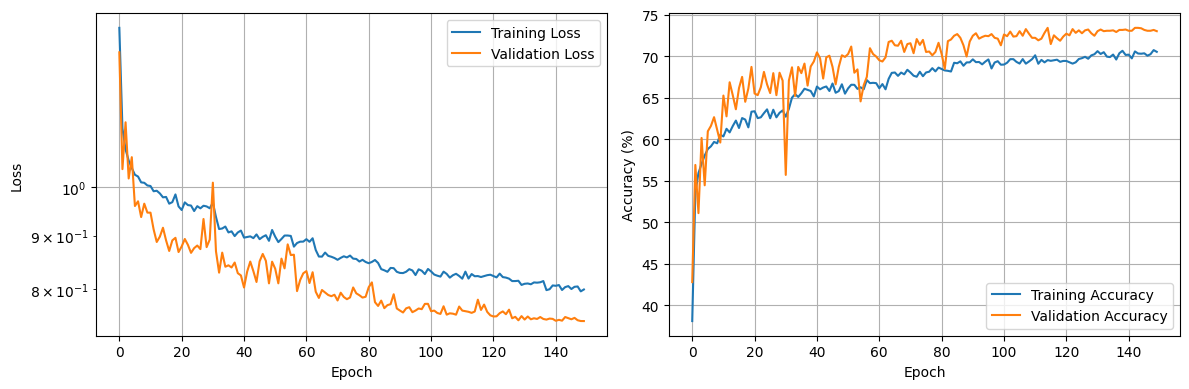

In [ ]:
# plot loss and accuracy vs epoch for training and validation

# Plot loss and accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Training Loss')
plt.plot(valid_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.yscale('log')
plt.grid()
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(valid_accuracies, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()



plt.tight_layout()
plt.grid()
plt.show()

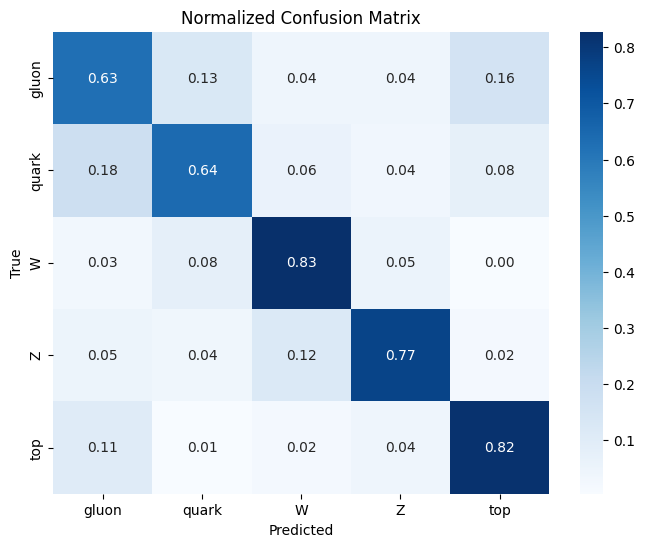

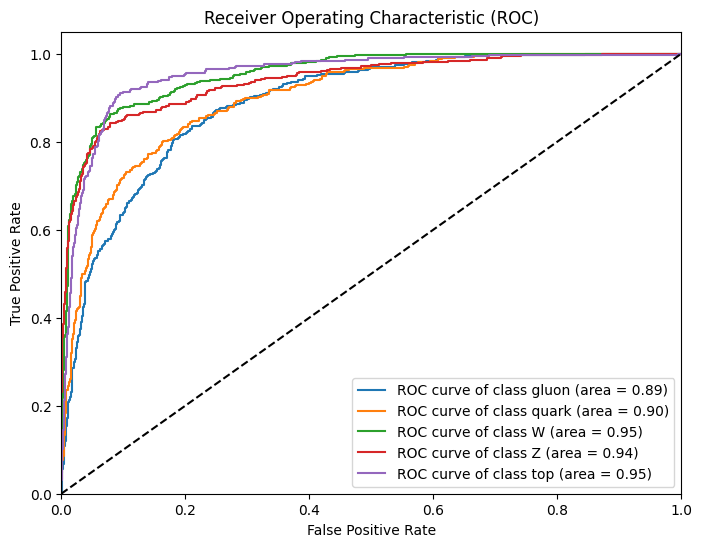

In [ ]:
# Load the best saved model
model.load_state_dict(torch.load('best_model_gnn.pth'))
model.eval()

# Evaluate on test set
y_true = []
y_pred = []
y_score = [] # For ROC curve

with torch.no_grad():
    for batch in testloader:
        batch = batch.to(device)
        outputs = model(batch)
        _, predicted = torch.max(outputs.data, 1)
        y_true.extend(batch.y.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())
        y_score.extend(F.softmax(outputs, dim=1).cpu().numpy())

import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] # normalize confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=labels_str, yticklabels=labels_str)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Normalized Confusion Matrix')
plt.show()

# ROC curve

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
n_classes = 5
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(np.array(y_true) == i, np.array(y_score)[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curves
plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label='ROC curve of class {0} (area = {1:0.2f})'
             ''.format(labels_str[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

## Visualization

*   **Node Embedding:** As data passes through the GNN layers, the model learns a high-dimensional vector representation (an "embedding") for each node (jet constituent). This vector captures complex features and relationships of that particle within the context of its neighbors.
*   **Magnitude/Norm:** Since we can't easily visualize high-dimensional vectors directly, we reduce each vector to a single scalar value: its magnitude (or length). A larger magnitude generally indicates a more prominent, distinct, or "active" feature in the learned representation, while a smaller magnitude suggests a less emphasized feature.
*   **Color Scale:** The color scale maps these magnitudes to visual colors, allowing you to see which particles have strong or weak representations in the GNN's internal processing. This helps you understand how the model is interpreting and weighting different parts of the jet based on its learned features, even when the original input features were different (like log(pt) in the first graph).

Original Graph (eta-phi colored by log(pt))


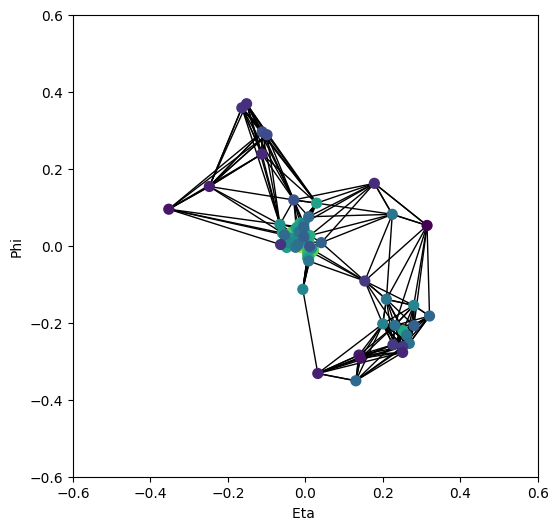

Embedded Graph (eta-phi colored by embedding magnitude)


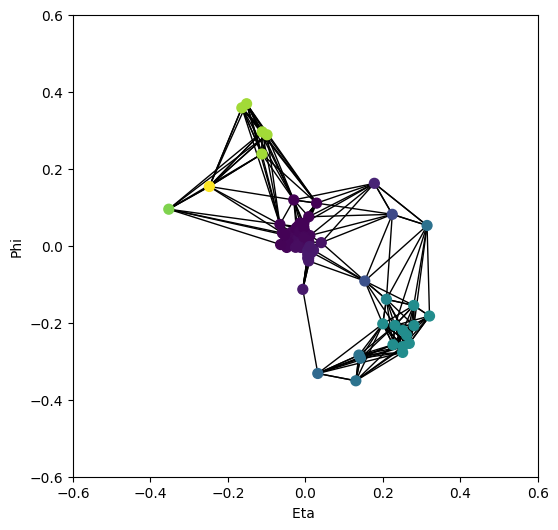

In [ ]:
def get_gnn_node_embeddings(model, data):
    # Ensure model is in evaluation mode
    model.eval()
    with torch.no_grad():
        pos, feat, edge_index, batch = data.pos, data.x.unsqueeze(1) , data.edge_index, data.batch
        feat = torch.cat((feat, pos), dim=1)

        feat = F.relu(model.pre_feat(feat))
        feat = F.relu(model.pre_feat2(feat))

        x = F.relu(model.conv1(feat, edge_index))
        x = model.bn1(x)
        x = F.relu(model.conv2(x, edge_index))
        x = model.bn2(x)
        x = F.relu(model.conv3(x, edge_index))
        x = model.bn3(x)
        return x

# Get the sample data
data_sample = trainset[sample_index].to(device)

# Visualize the original graph (eta-phi plane colored by log(pt))
print("Original Graph (eta-phi colored by log(pt))")
visualize_points(data_sample.pos.cpu(), data_sample.x.cpu(), data_sample.edge_index.cpu())

# Get node embeddings from the trained GNN model
node_embeddings = get_gnn_node_embeddings(model, data_sample)

# Visualize the embedded graph (eta-phi colored by embedding magnitude)
# For visualization, we can use the norm of the embedding vector as a scalar value
print("Embedded Graph (eta-phi colored by embedding magnitude)")
visualize_points(data_sample.pos.cpu(), node_embeddings.norm(dim=1).cpu(), data_sample.edge_index.cpu())

## Possible next steps

- How do loss and accuracy change when using only ($\eta$, $\phi$) or when adding additional node features? What feature is more relevant?
- What happens if you change the number of nearest neighbours to consider? Does increasing the number of KNN improve the perfmance or it just adds noise?
- Introduce the attention mechanism by changing the nodes from `GCNConv` to `GATConv`. What particles receive more attention (closer in space? higher transverse momentum)? plot colored links to show what connection matters most.
- Try to increase the number of layers up to 6 or 8. Is there risk of *oversmooting*? If the layers become too many, all nodes end up having the same embeddings and they become indistinguishable.
- Once the overall performance are satisfactory, isolate and plot the jets that are wrongly classified. Comment the shape of such jets: are they special for some reason?
- What happens if the adjacency matrix is set to 0? What happens to the overall performance if we shut down all the connections? Comment the importance of the spatial inductive bias.
